# E-Commerce Recommendation System

# Code 1: Explore the Dataset

In this section, we load the Online Retail dataset and understand its
structure, dimensions, columns, data types, statistical information,
and unique values.

In [3]:
# ============================================================
# 1. EXPLORE THE DATASET
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 40)

sns.set_theme(style="whitegrid")

# Load dataset
file_path = "/content/Online Retail.xlsx"
df = pd.read_excel(file_path, engine='openpyxl')

print("=" * 70)
print("DATASET EXPLORATION")
print("=" * 70)

# Basic shape
print(f"\nNumber of Rows    : {df.shape[0]:,}")
print(f"Number of Columns : {df.shape[1]}")

# First 5 records
print("\nFirst 5 Records:")
display(df.head())

# Last 5 records
print("\nLast 5 Records:")
display(df.tail())

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").transpose())

# Unique values
print("\nUnique Values:")
for column in df.columns:
    print(f"{column:15} : {df[column].nunique():,}")

DATASET EXPLORATION

Number of Rows    : 541,909
Number of Columns : 8

First 5 Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Last 5 Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France



Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Unique Values:
InvoiceNo       : 25,900
StockCode       : 4,070
Description     : 4,223
Quantity        : 722
InvoiceDate     : 23,260
UnitPrice       : 1,630
CustomerID      : 4,372
Country         : 38


# Code 2: Missing / Null Value Analysis

Missing values can affect data analysis and machine learning models.
In this section, we identify the number and percentage of missing
values in each column before making any cleaning decisions.

MISSING / NULL VALUE ANALYSIS

Missing Value Summary:


,Missing Count,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00



Total Missing Values: 136,534

Columns with Missing Values:


,Missing Count,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27


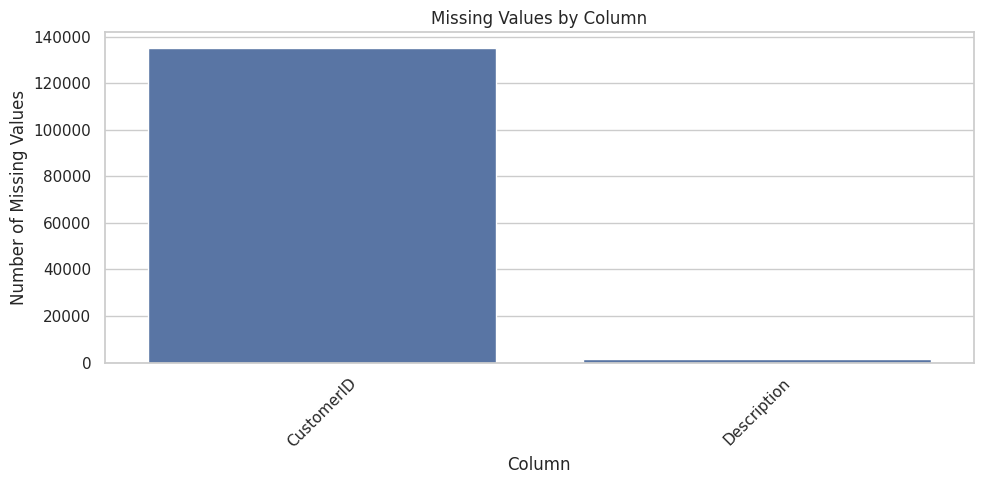


Sample records with missing CustomerID:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom



Sample records with missing Description:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom


In [4]:
# ============================================================
# 2. MISSING / NULL VALUE ANALYSIS
# ============================================================

print("=" * 70)
print("MISSING / NULL VALUE ANALYSIS")
print("=" * 70)

# Calculate missing values
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

# Create summary table
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage.round(2)
}).sort_values("Missing Count", ascending=False)

print("\nMissing Value Summary:")
display(missing_summary)

# Total missing values
total_missing = df.isnull().sum().sum()

print(f"\nTotal Missing Values: {total_missing:,}")

# Columns containing missing values
columns_with_missing = missing_summary[
    missing_summary["Missing Count"] > 0
]

if len(columns_with_missing) > 0:
    print("\nColumns with Missing Values:")
    display(columns_with_missing)
else:
    print("\nNo missing values found.")

# Visualize missing values
if len(columns_with_missing) > 0:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        x=columns_with_missing.index,
        y=columns_with_missing["Missing Count"]
    )

    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Show sample records with missing values
for column in columns_with_missing.index:

    print(f"\nSample records with missing {column}:")
    display(df[df[column].isnull()].head(5))

# Code 3: Duplicate Record Analysis and Removal

Duplicate records can cause transactions to be counted more than once
and may distort statistical analysis and visualizations.

We first identify exact duplicate rows and then remove them while
keeping the original dataset unchanged.

In [5]:
# ============================================================
# 3. DUPLICATE ANALYSIS AND REMOVAL
# ============================================================

print("=" * 70)
print("DUPLICATE RECORD ANALYSIS")
print("=" * 70)

# Count duplicate records
duplicate_count = df.duplicated().sum()
duplicate_percentage = (duplicate_count / len(df)) * 100

print(f"\nTotal Duplicate Records : {duplicate_count:,}")
print(f"Duplicate Percentage    : {duplicate_percentage:.2f}%")

# Display duplicate records
if duplicate_count > 0:

    print("\nSample Duplicate Records:")
    display(
        df[df.duplicated(keep=False)]
        .sort_values(by=df.columns.tolist())
        .head(10)
    )

else:
    print("\nNo duplicate records found.")

# Create cleaned dataframe
# Original df remains unchanged
df_clean = df.drop_duplicates().copy()

# Reset index
df_clean.reset_index(drop=True, inplace=True)

# Summary
print("\n" + "-" * 50)
print("DUPLICATE REMOVAL SUMMARY")
print("-" * 50)

print(f"Original Records       : {len(df):,}")
print(f"Duplicate Records      : {duplicate_count:,}")
print(f"Records After Removal  : {len(df_clean):,}")
print(f"Remaining Duplicates   : {df_clean.duplicated().sum():,}")

print("\nCleaned Dataset Preview:")
display(df_clean.head())

DUPLICATE RECORD ANALYSIS

Total Duplicate Records : 5,268
Duplicate Percentage    : 0.97%

Sample Duplicate Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom



--------------------------------------------------
DUPLICATE REMOVAL SUMMARY
--------------------------------------------------
Original Records       : 541,909
Duplicate Records      : 5,268
Records After Removal  : 536,641
Remaining Duplicates   : 0

Cleaned Dataset Preview:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


# Code 4: Data Quality Analysis

Apart from missing and duplicate records, transaction datasets can
contain unusual values such as cancelled invoices, negative quantities,
or zero/negative prices.

This section identifies such records before performing EDA.

In [6]:
# ============================================================
# 4. DATA QUALITY ANALYSIS
# ============================================================

print("=" * 70)
print("DATA QUALITY ANALYSIS")
print("=" * 70)

# Cancelled invoices
cancelled = df_clean["InvoiceNo"].astype(str).str.startswith("C")

# Negative or zero quantity
invalid_quantity = df_clean["Quantity"] <= 0

# Negative or zero price
invalid_price = df_clean["UnitPrice"] <= 0

# Missing customer
missing_customer = df_clean["CustomerID"].isnull()

# Missing description
missing_description = df_clean["Description"].isnull()

# Create quality summary
quality_summary = pd.DataFrame({
    "Data Quality Issue": [
        "Cancelled Invoices",
        "Quantity <= 0",
        "UnitPrice <= 0",
        "Missing CustomerID",
        "Missing Description"
    ],
    "Count": [
        cancelled.sum(),
        invalid_quantity.sum(),
        invalid_price.sum(),
        missing_customer.sum(),
        missing_description.sum()
    ]
})

quality_summary["Percentage"] = (
    quality_summary["Count"] / len(df_clean) * 100
).round(2)

print("\nData Quality Summary:")
display(quality_summary)

# Show samples
print("\nSample Cancelled Transactions:")
display(df_clean[cancelled].head(5))

print("\nSample Records with Quantity <= 0:")
display(df_clean[invalid_quantity].head(5))

print("\nSample Records with UnitPrice <= 0:")
display(df_clean[invalid_price].head(5))

DATA QUALITY ANALYSIS

Data Quality Summary:


,Data Quality Issue,Count,Percentage
0,Cancelled Invoices,9251,1.72
1,Quantity <= 0,10587,1.97
2,UnitPrice <= 0,2512,0.47
3,Missing CustomerID,135037,25.16
4,Missing Description,1454,0.27



Sample Cancelled Transactions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom



Sample Records with Quantity <= 0:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom



Sample Records with UnitPrice <= 0:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
605,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1934,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1935,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1936,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1951,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom


# Code 5: Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand customer behavior,
product performance, sales patterns, geographical distribution, and
transaction trends in the e-commerce dataset.

EXPLORATORY DATA ANALYSIS (EDA)

KEY BUSINESS METRICS
--------------------------------------------------
Total Sales          : £9,726,006.95
Total Quantity       : 5,162,502
Unique Invoices      : 25,900
Unique Products      : 4,070
Unique Customers     : 4,372
Unique Countries     : 38

TOP 10 PRODUCTS BY NUMBER OF TRANSACTIONS


,Transaction Count
StockCode,
85123A,2301
22423,2192
85099B,2156
47566,1720
20725,1626
84879,1489
22720,1469
22197,1468
21212,1367


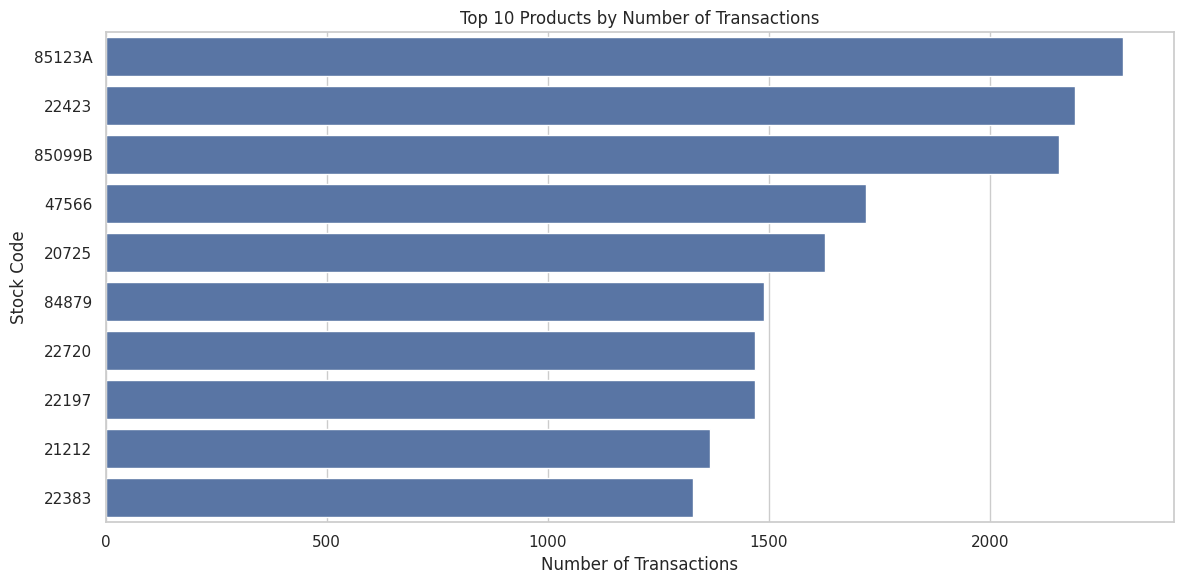


TOP 10 PRODUCTS BY QUANTITY SOLD


,Total Quantity
StockCode,
22197,56427
84077,53751
85099B,47260
85123A,38811
84879,36122
21212,36016
23084,30597
22492,26437
22616,26299


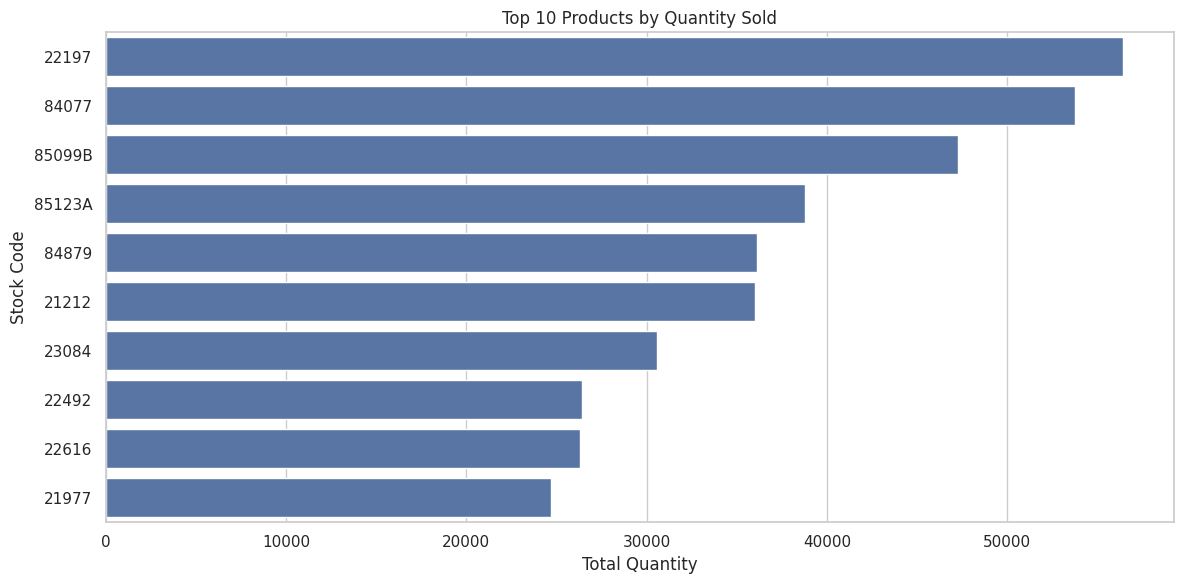


TOP 10 PRODUCTS BY SALES


,Total Sales
StockCode,
DOT,206245.48
22423,164459.49
47566,98243.88
85123A,97838.45
85099B,92175.79
23084,66661.63
POST,66230.64
22086,63715.24
84879,58792.42


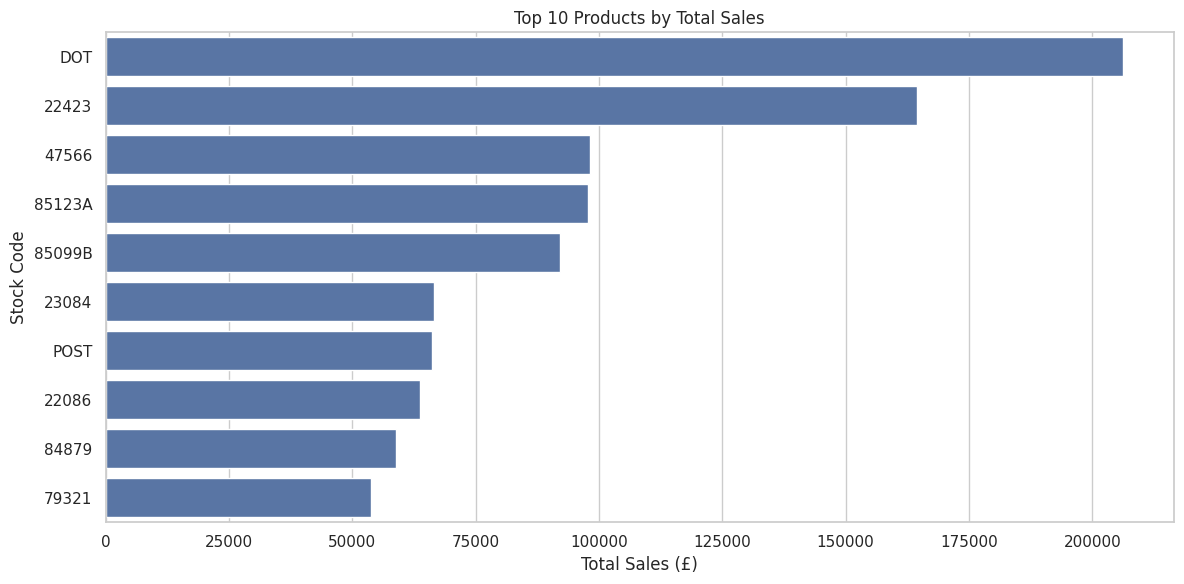


TOP 10 CUSTOMERS BY SPENDING


,Total Spending
CustomerID,
14646.0,279489.02
18102.0,256438.49
17450.0,187322.17
14911.0,132458.73
12415.0,123725.45
14156.0,113214.59
17511.0,88125.38
16684.0,65892.08
13694.0,62690.54


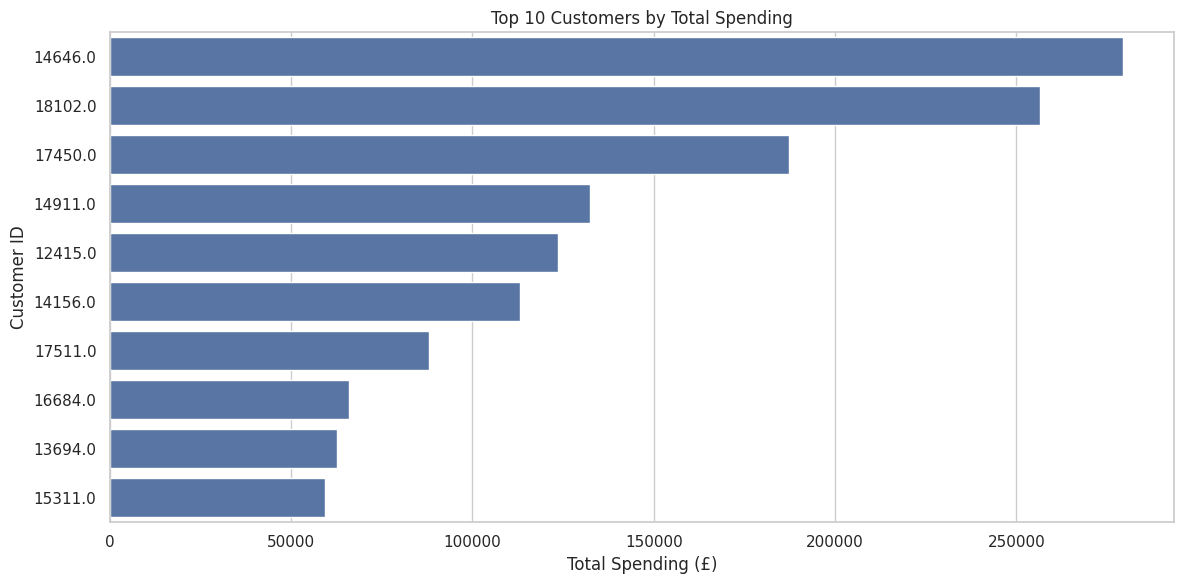


TOP 10 COUNTRIES BY TRANSACTIONS


,Transaction Count
Country,
United Kingdom,23494
Germany,603
France,461
EIRE,360
Belgium,119
Spain,105
Netherlands,101
Switzerland,74
Portugal,71


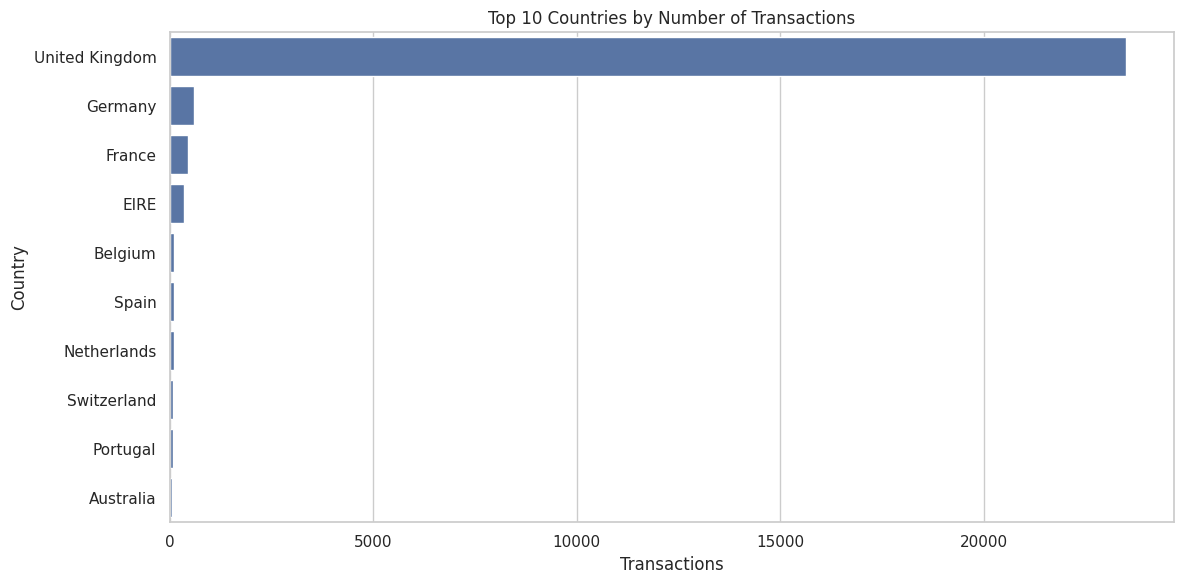


TOP 10 COUNTRIES BY SALES


,Total Sales
Country,
United Kingdom,8167128.184
Netherlands,284661.540
EIRE,262993.380
Germany,221509.470
France,197317.110
Australia,137009.770
Switzerland,56363.050
Spain,54756.030
Belgium,40910.960


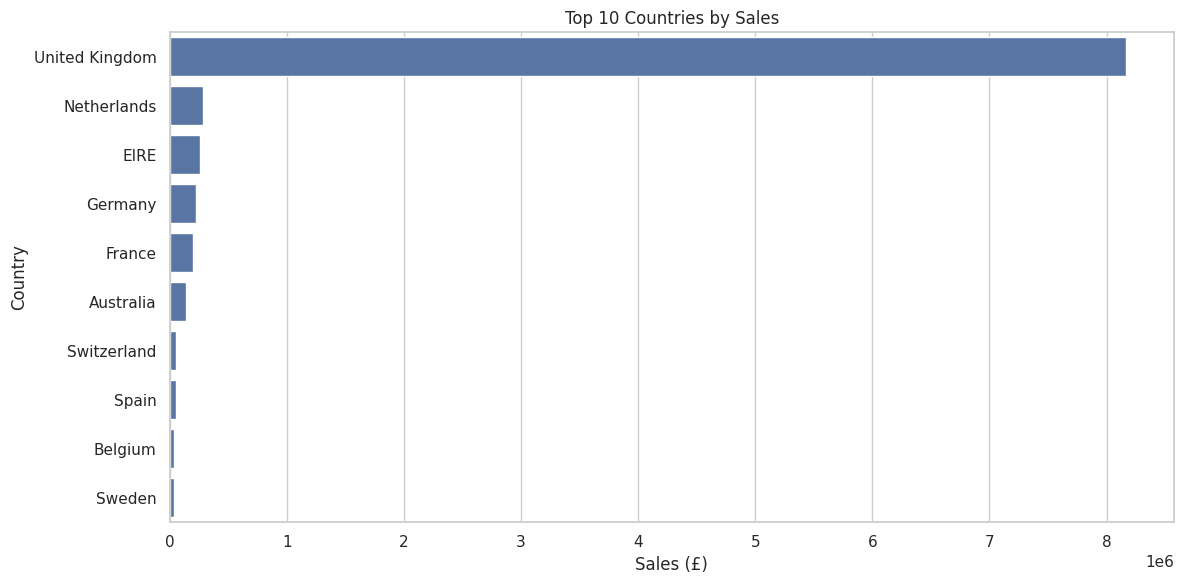


MONTHLY SALES


,Year,Month,TotalAmount,YearMonth
0,2010,12,746723.610,2010-12
1,2011,1,558448.560,2011-01
2,2011,2,497026.410,2011-02
3,2011,3,682013.980,2011-03
4,2011,4,492367.841,2011-04
5,2011,5,722094.100,2011-05
6,2011,6,689977.230,2011-06
7,2011,7,680156.991,2011-07
8,2011,8,681386.460,2011-08
9,2011,9,1017596.682,2011-09


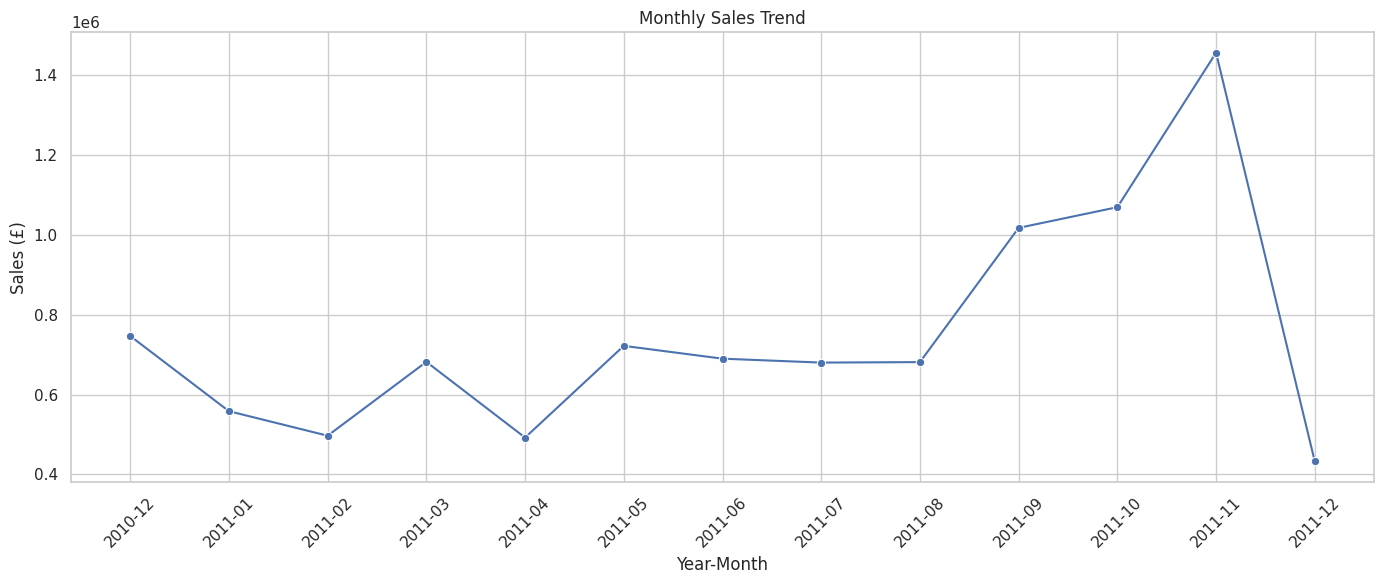

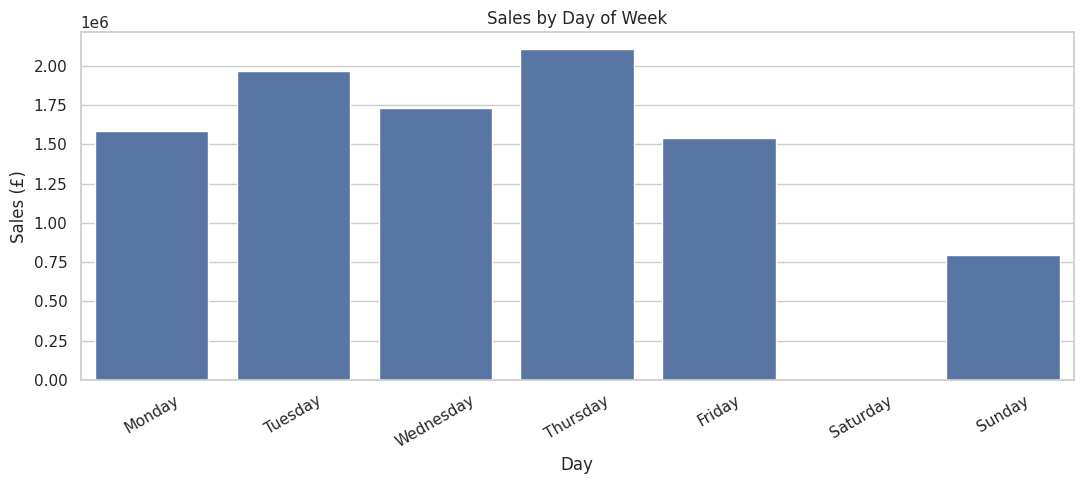

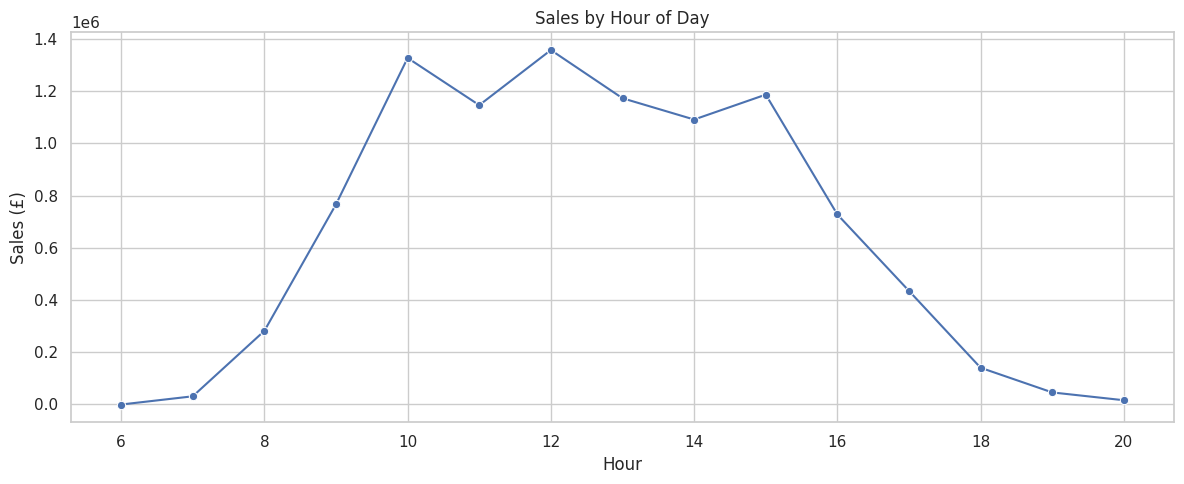

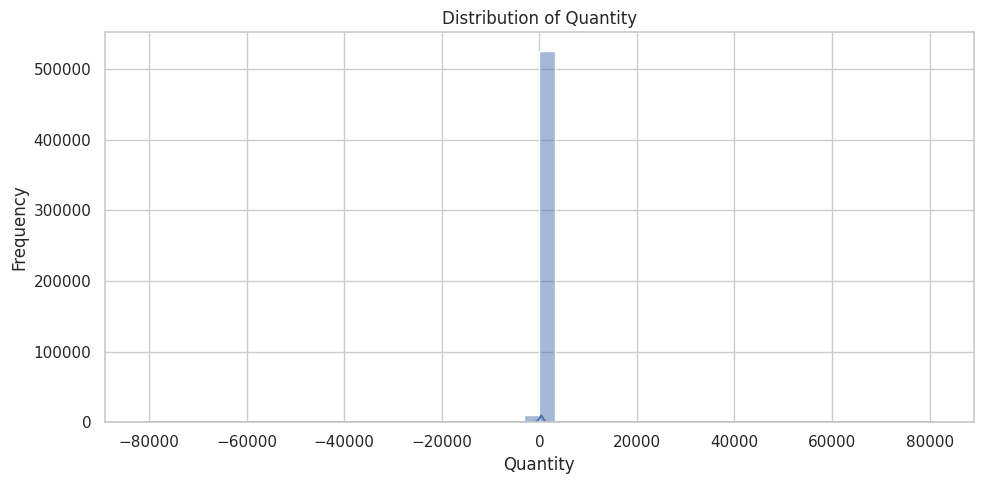

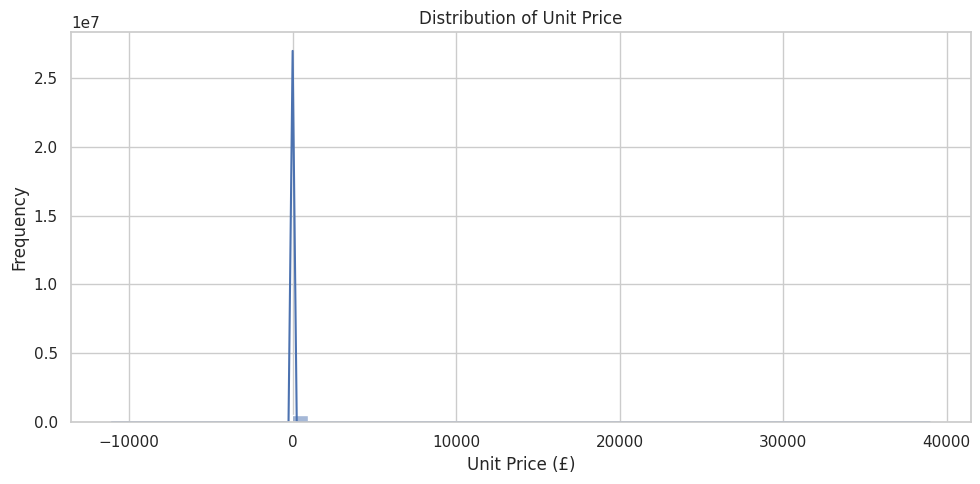

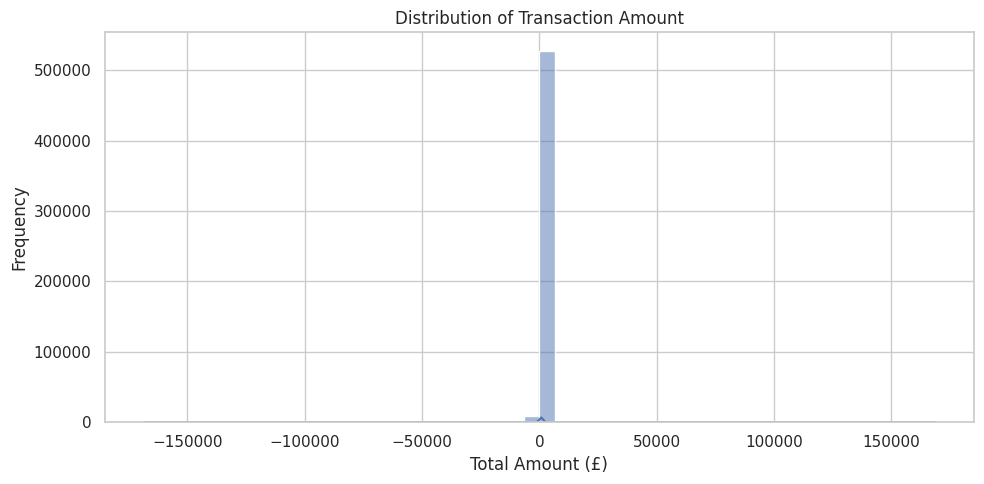


EDA COMPLETED

Total Records        : 536,641
Total Sales          : £9,726,006.95
Total Quantity       : 5,162,502
Unique Invoices      : 25,900
Unique Products      : 4,070
Unique Customers     : 4,372
Unique Countries     : 38



In [7]:
# ============================================================
# 5. EXPLORATORY DATA ANALYSIS
# ============================================================

print("=" * 70)
print("EXPLORATORY DATA ANALYSIS (EDA)")
print("=" * 70)

# ------------------------------------------------------------
# Create Total Amount
# ------------------------------------------------------------

df_clean["TotalAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# ------------------------------------------------------------
# BASIC BUSINESS METRICS
# ------------------------------------------------------------

print("\nKEY BUSINESS METRICS")
print("-" * 50)

print(f"Total Sales          : £{df_clean['TotalAmount'].sum():,.2f}")
print(f"Total Quantity       : {df_clean['Quantity'].sum():,.0f}")
print(f"Unique Invoices      : {df_clean['InvoiceNo'].nunique():,}")
print(f"Unique Products      : {df_clean['StockCode'].nunique():,}")
print(f"Unique Customers     : {df_clean['CustomerID'].nunique():,}")
print(f"Unique Countries     : {df_clean['Country'].nunique():,}")

# ------------------------------------------------------------
# 5.1 TOP 10 PRODUCTS BY TRANSACTION COUNT
# ------------------------------------------------------------

top_products = (
    df_clean.groupby("StockCode")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 PRODUCTS BY NUMBER OF TRANSACTIONS")
display(top_products.to_frame("Transaction Count"))

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index.astype(str)
)

plt.title("Top 10 Products by Number of Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Stock Code")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.2 TOP 10 PRODUCTS BY QUANTITY SOLD
# ------------------------------------------------------------

top_quantity = (
    df_clean.groupby("StockCode")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 PRODUCTS BY QUANTITY SOLD")
display(top_quantity.to_frame("Total Quantity"))

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_quantity.values,
    y=top_quantity.index.astype(str)
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity")
plt.ylabel("Stock Code")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.3 TOP 10 PRODUCTS BY SALES
# ------------------------------------------------------------

top_sales_products = (
    df_clean.groupby("StockCode")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 PRODUCTS BY SALES")
display(top_sales_products.to_frame("Total Sales"))

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_sales_products.values,
    y=top_sales_products.index.astype(str)
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales (£)")
plt.ylabel("Stock Code")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.4 TOP 10 CUSTOMERS BY SPENDING
# ------------------------------------------------------------

top_customers = (
    df_clean.groupby("CustomerID")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 CUSTOMERS BY SPENDING")
display(top_customers.to_frame("Total Spending"))

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_customers.values,
    y=top_customers.index.astype(str)
)

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Total Spending (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.5 TOP 10 COUNTRIES BY NUMBER OF TRANSACTIONS
# ------------------------------------------------------------

top_countries = (
    df_clean.groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 COUNTRIES BY TRANSACTIONS")
display(top_countries.to_frame("Transaction Count"))

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Number of Transactions")
plt.xlabel("Transactions")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.6 TOP 10 COUNTRIES BY SALES
# ------------------------------------------------------------

country_sales = (
    df_clean.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 COUNTRIES BY SALES")
display(country_sales.to_frame("Total Sales"))

plt.figure(figsize=(12, 6))

sns.barplot(
    x=country_sales.values,
    y=country_sales.index
)

plt.title("Top 10 Countries by Sales")
plt.xlabel("Sales (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.7 MONTHLY SALES TREND
# ------------------------------------------------------------

df_clean["Year"] = df_clean["InvoiceDate"].dt.year
df_clean["Month"] = df_clean["InvoiceDate"].dt.month

monthly_sales = (
    df_clean.groupby(["Year", "Month"])["TotalAmount"]
    .sum()
    .reset_index()
)

monthly_sales["YearMonth"] = (
    monthly_sales["Year"].astype(str)
    + "-"
    + monthly_sales["Month"].astype(str).str.zfill(2)
)

print("\nMONTHLY SALES")
display(monthly_sales.head(10))

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="TotalAmount",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Sales (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.8 SALES BY DAY OF WEEK
# ------------------------------------------------------------

df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_sales = (
    df_clean.groupby("DayOfWeek")["TotalAmount"]
    .sum()
    .reindex(day_order)
)

plt.figure(figsize=(11, 5))

sns.barplot(
    x=day_sales.index,
    y=day_sales.values
)

plt.title("Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Sales (£)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.9 SALES BY HOUR
# ------------------------------------------------------------

df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

hour_sales = (
    df_clean.groupby("Hour")["TotalAmount"]
    .sum()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hour_sales.index,
    y=hour_sales.values,
    marker="o"
)

plt.title("Sales by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Sales (£)")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.10 QUANTITY DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["Quantity"],
    bins=50,
    kde=True
)

plt.title("Distribution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.11 UNIT PRICE DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["UnitPrice"],
    bins=50,
    kde=True
)

plt.title("Distribution of Unit Price")
plt.xlabel("Unit Price (£)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.12 SALES DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["TotalAmount"],
    bins=50,
    kde=True
)

plt.title("Distribution of Transaction Amount")
plt.xlabel("Total Amount (£)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# FINAL EDA SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EDA COMPLETED")
print("=" * 70)

print(f"""
Total Records        : {len(df_clean):,}
Total Sales          : £{df_clean['TotalAmount'].sum():,.2f}
Total Quantity       : {df_clean['Quantity'].sum():,.0f}
Unique Invoices      : {df_clean['InvoiceNo'].nunique():,}
Unique Products      : {df_clean['StockCode'].nunique():,}
Unique Customers     : {df_clean['CustomerID'].nunique():,}
Unique Countries     : {df_clean['Country'].nunique():,}
""")

# Code 6: ML Library Imports and Configuration

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 40)
sns.set_theme(style="whitegrid")

# Code 7: Prepare ML Data

In [9]:
# Ensure df_clean exists. If not, load raw data and clean.
if 'df_clean' not in locals() or df_clean.empty:
    print("df_clean not found or is empty. Re-creating from raw data.")
    file_path = "/content/Online Retail.xlsx"
    try:
        df_raw = pd.read_excel(file_path)
        df_raw['InvoiceDate'] = pd.to_datetime(df_raw['InvoiceDate'])
        df_clean = df_raw.drop_duplicates().copy()
        df_clean.reset_index(drop=True, inplace=True)
        print("df_clean re-created successfully.")
    except FileNotFoundError:
        raise FileNotFoundError(f"Error: Data file not found at {file_path}. Please ensure it's uploaded.")
    except Exception as e:
        raise Exception(f"Error during df_clean recreation: {e}")

# Ensure TotalAmount is calculated on df_clean
if 'TotalAmount' not in df_clean.columns:
    df_clean['TotalAmount'] = df_clean['Quantity'] * df_clean['UnitPrice']

# Create ml_df from df_clean
ml_df = df_clean.copy()

# Extract date features from InvoiceDate
if 'InvoiceDate' in ml_df.columns and pd.api.types.is_datetime64_any_dtype(ml_df['InvoiceDate']):
    ml_df['Year'] = ml_df['InvoiceDate'].dt.year
    ml_df['Month'] = ml_df['InvoiceDate'].dt.month
    ml_df['Day'] = ml_df['InvoiceDate'].dt.day
    ml_df['DayOfWeek'] = ml_df['InvoiceDate'].dt.dayofweek # Monday=0, Sunday=6
    ml_df['Hour'] = ml_df['InvoiceDate'].dt.hour
else:
    print("Warning: InvoiceDate column not found or not in datetime format in ml_df. Skipping date feature extraction.")

# Drop columns not needed or replaced by extracted features
ml_df = ml_df.drop(columns=['InvoiceNo', 'InvoiceDate', 'Description'], errors='ignore')

print("ML Data Prepared (first 5 rows):")
display(ml_df.head())
print(f"Shape of ml_df: {ml_df.shape}")

ML Data Prepared (first 5 rows):


,StockCode,Quantity,UnitPrice,CustomerID,Country,TotalAmount,Year,Month,DayOfWeek,Hour,Day
0,85123A,6,2.55,17850.0,United Kingdom,15.30,2010,12,2,8,1
1,71053,6,3.39,17850.0,United Kingdom,20.34,2010,12,2,8,1
2,84406B,8,2.75,17850.0,United Kingdom,22.00,2010,12,2,8,1
3,84029G,6,3.39,17850.0,United Kingdom,20.34,2010,12,2,8,1
4,84029E,6,3.39,17850.0,United Kingdom,20.34,2010,12,2,8,1


Shape of ml_df: (536641, 11)


# Code 8: Create Rating Proxy

Rating_Proxy is used because the dataset does not contain actual customer ratings.

Sample of Customers with their Behavioral Features and Rating_Proxy (first 10):


,CustomerID,Total_Spending,Total_Quantity,Number_of_Orders,Number_of_Products,Average_Order_Value,Average_Unit_Price,Purchase_Frequency,Rating_Proxy
0,12346.0,0.00,0,1,1,0.000000,0.000000,2,1.035178
1,12347.0,4310.00,2458,103,103,41.844660,1.753458,182,4.516571
2,12348.0,1797.24,2341,22,22,81.692727,0.767723,31,3.040324
3,12349.0,1757.55,631,73,73,24.076027,2.785341,73,3.888283
4,12350.0,334.40,197,17,17,19.670588,1.697462,17,2.073620
5,12352.0,1545.41,470,59,59,26.193390,3.288106,95,3.858482
6,12353.0,89.00,20,4,4,22.250000,4.450000,4,1.170974
7,12354.0,1079.40,530,58,58,18.610345,2.036604,58,3.550021
8,12355.0,459.40,240,13,13,35.338462,1.914167,13,2.044894
9,12356.0,2811.43,1591,53,53,53.045849,1.767084,59,3.805023



Distribution of Rating_Proxy:


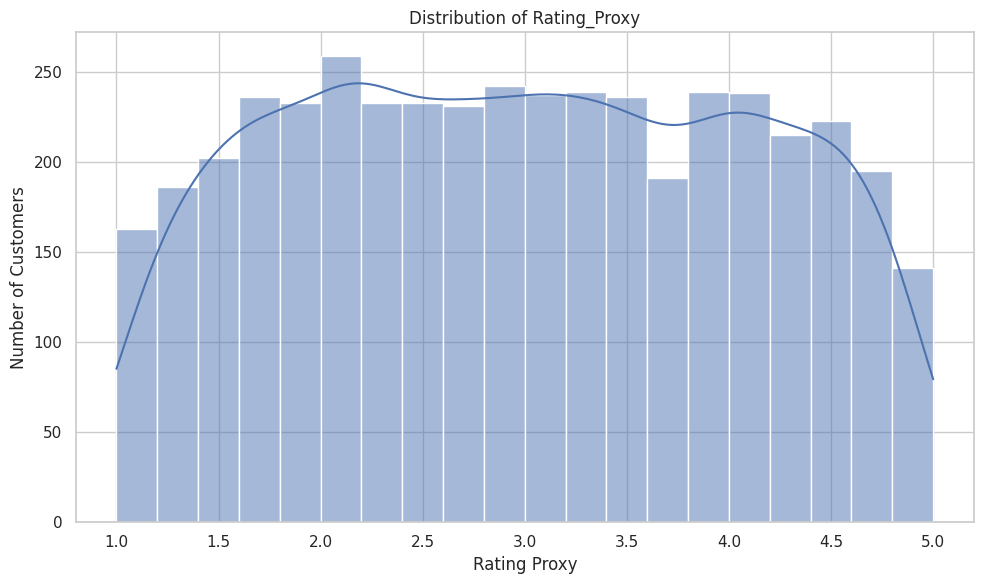

In [10]:
# Aggregate transaction information by CustomerID to create customer-level features
customer_df = ml_df.groupby('CustomerID').agg(
    Total_Spending=('TotalAmount', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Number_of_Orders=('StockCode', 'nunique'),
    Number_of_Products=('StockCode', 'nunique'),
    Purchase_Frequency=('StockCode', 'count')
).reset_index()

# Calculate Average Order Value and Average Unit Price (per customer)
customer_df['Average_Order_Value'] = customer_df['Total_Spending'] / customer_df['Number_of_Orders']
customer_df['Average_Unit_Price'] = customer_df['Total_Spending'] / customer_df['Total_Quantity']

# Handle potential NaN/Infinity from division by zero
customer_df.replace([np.inf, -np.inf], np.nan, inplace=True)
customer_df.fillna(0, inplace=True)

# Calculate percentile ranks for key behavioral features
customer_df['Spending_Rank'] = customer_df['Total_Spending'].rank(pct=True)
customer_df['Products_Rank'] = customer_df['Number_of_Products'].rank(pct=True)
customer_df['Frequency_Rank'] = customer_df['Purchase_Frequency'].rank(pct=True)

# Create a composite score (e.g., average of ranks)
customer_df['Composite_Score'] = (customer_df['Spending_Rank'] + customer_df['Products_Rank'] + customer_df['Frequency_Rank']) / 3

# Scale the composite score to a 1-5 rating proxy
min_score = customer_df['Composite_Score'].min()
max_score = customer_df['Composite_Score'].max()

if max_score == min_score:
    customer_df['Rating_Proxy'] = 3  # Assign a neutral rating if no variance
else:
    customer_df['Rating_Proxy'] = ((customer_df['Composite_Score'] - min_score) / (max_score - min_score) * 4) + 1

# Ensure Rating_Proxy is strictly between 1 and 5
customer_df['Rating_Proxy'] = np.clip(customer_df['Rating_Proxy'], 1, 5)

print("Sample of Customers with their Behavioral Features and Rating_Proxy (first 10):")
display(customer_df[[ 'CustomerID',
                        'Total_Spending',
                        'Total_Quantity',
                        'Number_of_Orders',
                        'Number_of_Products',
                        'Average_Order_Value',
                        'Average_Unit_Price',
                        'Purchase_Frequency',
                        'Rating_Proxy']].head(10))

print("\nDistribution of Rating_Proxy:")
plt.figure(figsize=(10, 6))
sns.histplot(customer_df['Rating_Proxy'], bins=20, kde=True)
plt.title('Distribution of Rating_Proxy')
plt.xlabel('Rating Proxy')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

# Code 9: Select Features

In [11]:
# Define the target variable (y)
y = customer_df['Rating_Proxy']

# Define the features (X) for the ML model
feature_cols = [
    'Total_Spending',
    'Total_Quantity',
    'Number_of_Orders',
    'Number_of_Products',
    'Average_Order_Value',
    'Average_Unit_Price',
    'Purchase_Frequency'
]

X = customer_df[feature_cols]

print("Selected Features (X) - first 5 rows:")
display(X.head())

print("\nTarget Variable (y) - first 5 rows:")
display(y.head())

print(f"\nNumber of features selected: {len(feature_cols)}")

Selected Features (X) - first 5 rows:


,Total_Spending,Total_Quantity,Number_of_Orders,Number_of_Products,Average_Order_Value,Average_Unit_Price,Purchase_Frequency
0,0.00,0,1,1,0.000000,0.000000,2
1,4310.00,2458,103,103,41.844660,1.753458,182
2,1797.24,2341,22,22,81.692727,0.767723,31
3,1757.55,631,73,73,24.076027,2.785341,73
4,334.40,197,17,17,19.670588,1.697462,17



Target Variable (y) - first 5 rows:


,Rating_Proxy
0,1.035178
1,4.516571
2,3.040324
3,3.888283
4,2.073620



Number of features selected: 7


# Code 10: Convert Features to Numerical Representation

In [12]:
# Define numerical features (all features in X are numerical)
numerical_features = X.columns.tolist()

# Create a preprocessing pipeline for numerical features
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')), # Handle any potential NaN values
    ('scaler', StandardScaler())
])

# Apply the preprocessing to the features X
X_preprocessed = numerical_transformer.fit_transform(X)

print("Preprocessing pipeline applied.")
print(f"Shape of preprocessed features: {X_preprocessed.shape}")
print("First 5 rows of preprocessed features (scaled numerical values):")
display(pd.DataFrame(X_preprocessed, columns=numerical_features).head())

Preprocessing pipeline applied.
Shape of preprocessed features: (4372, 7)
First 5 rows of preprocessed features (scaled numerical values):


,Total_Spending,Total_Quantity,Number_of_Orders,Number_of_Products,Average_Order_Value,Average_Unit_Price,Purchase_Frequency
0,-0.230420,-0.239517,-0.704922,-0.704922,-0.243474,-0.058718,-0.392056
1,0.294055,0.286544,0.489243,0.489243,-0.008405,-0.036401,0.393293
2,-0.011717,0.261504,-0.459064,-0.459064,0.215447,-0.048947,-0.265527
3,-0.016547,-0.104470,0.138018,0.138018,-0.108223,-0.023268,-0.082279
4,-0.189727,-0.197355,-0.517602,-0.517602,-0.132971,-0.037114,-0.326610


# Code 11: Split Training and Testing Data

In [13]:
# Split the preprocessed data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_preprocessed, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Dataset split into training and testing sets:")
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples : {X_test.shape[0]}")
print(f"Number of features: {X_train.shape[1]}")

Dataset split into training and testing sets:
Training samples: 3497
Testing samples : 875
Number of features: 7


# Code 12: Train Linear Regression Model

In [14]:
# Initialize and train Linear Regression model
linear_reg_model = LinearRegression()
print("Training Linear Regression model...")
linear_reg_model.fit(X_train, y_train)
print("Linear Regression model trained successfully.")

Training Linear Regression model...
Linear Regression model trained successfully.


# Code 13: Train Random Forest Regression Model

In [15]:
# Initialize and train Random Forest Regressor model
random_forest_model = RandomForestRegressor(random_state=RANDOM_STATE)
print("Training Random Forest Regressor model...")
random_forest_model.fit(X_train, y_train)
print("Random Forest Regressor model trained successfully.")

Training Random Forest Regressor model...
Random Forest Regressor model trained successfully.


# Code 14: Predict Ratings

In [16]:
predictions = {}

print("Generating predictions on the test set:")
predictions["Linear Regression"] = linear_reg_model.predict(X_test)
print("- Predictions for Linear Regression generated.")

predictions["Random Forest Regressor"] = random_forest_model.predict(X_test)
print("- Predictions for Random Forest Regressor generated.")

Generating predictions on the test set:
- Predictions for Linear Regression generated.
- Predictions for Random Forest Regressor generated.


# Code 15: Calculate MAE

In [17]:
model_metrics = {}

print("Calculating Mean Absolute Error (MAE):")
for name, y_pred in predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    if name not in model_metrics: model_metrics[name] = {}
    model_metrics[name]['MAE'] = mae
    print(f"- {name} MAE: {mae:.4f}")

Calculating Mean Absolute Error (MAE):
- Linear Regression MAE: 0.5817
- Random Forest Regressor MAE: 0.0184


# Code 16: Calculate MSE

In [18]:
print("Calculating Mean Squared Error (MSE):")
for name, y_pred in predictions.items():
    mse = mean_squared_error(y_test, y_pred)
    if name not in model_metrics: model_metrics[name] = {}
    model_metrics[name]['MSE'] = mse
    print(f"- {name} MSE: {mse:.4f}")

Calculating Mean Squared Error (MSE):
- Linear Regression MSE: 0.7754
- Random Forest Regressor MSE: 0.0013


# Code 17: Calculate RMSE

In [19]:
print("Calculating Root Mean Squared Error (RMSE):")
for name, y_pred in predictions.items():
    rmse = np.sqrt(model_metrics[name]['MSE'])
    if name not in model_metrics: model_metrics[name] = {}
    model_metrics[name]['RMSE'] = rmse
    print(f"- {name} RMSE: {rmse:.4f}")

Calculating Root Mean Squared Error (RMSE):
- Linear Regression RMSE: 0.8806
- Random Forest Regressor RMSE: 0.0356


# Code 18: Compare Models

In [20]:
# Create a DataFrame for model comparison
model_comparison_df = pd.DataFrame(model_metrics).transpose()
model_comparison_df.index.name = 'Model'

print("\nModel Comparison Table (sorted by RMSE):")
display(model_comparison_df.sort_values(by='RMSE', ascending=True).round(4))


Model Comparison Table (sorted by RMSE):


,MAE,MSE,RMSE
Model,,,
Random Forest Regressor,0.0184,0.0013,0.0356
Linear Regression,0.5817,0.7754,0.8806


# Code 19: Visualize Model Performance

Visualizing Model Performance:


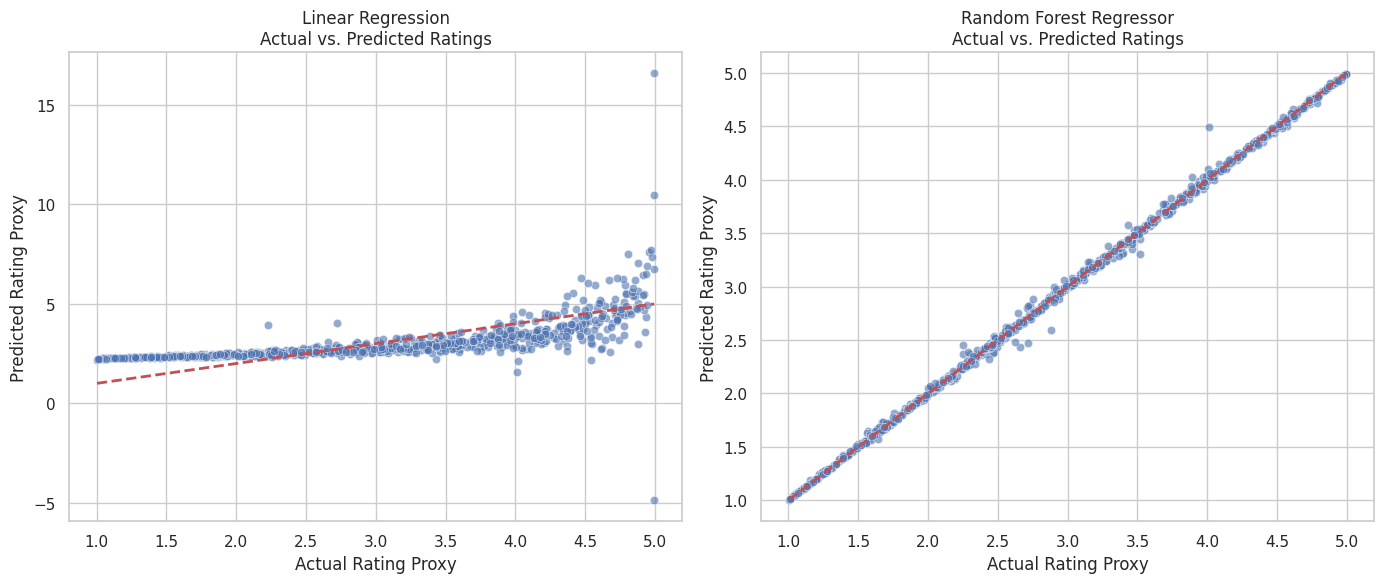

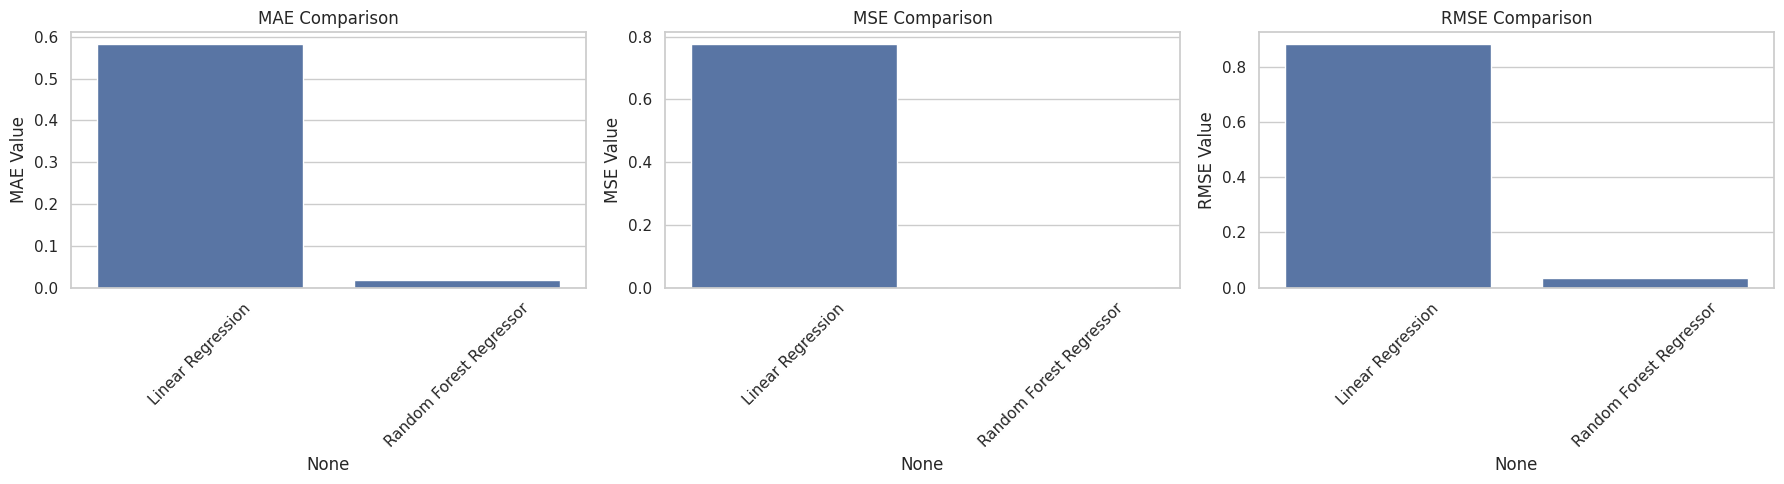

In [21]:
print("Visualizing Model Performance:")

# Actual vs Predicted Plots
plt.figure(figsize=(14, 6))

i = 1
for name in ["Linear Regression", "Random Forest Regressor"]:
    y_pred = predictions[name]
    plt.subplot(1, 2, i)
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2) # Ideal line
    plt.title(f'{name}\nActual vs. Predicted Ratings')
    plt.xlabel('Actual Rating Proxy')
    plt.ylabel('Predicted Rating Proxy')
    i += 1
plt.tight_layout()
plt.show()

# MAE, MSE, RMSE Comparison Bar Charts
metrics_df_for_plot = pd.DataFrame(model_metrics).transpose()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(x=metrics_df_for_plot.index, y=metrics_df_for_plot['MAE'], ax=axes[0])
axes[0].set_title('MAE Comparison')
axes[0].set_ylabel('MAE Value')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(x=metrics_df_for_plot.index, y=metrics_df_for_plot['MSE'], ax=axes[1])
axes[1].set_title('MSE Comparison')
axes[1].set_ylabel('MSE Value')
axes[1].tick_params(axis='x', rotation=45)

sns.barplot(x=metrics_df_for_plot.index, y=metrics_df_for_plot['RMSE'], ax=axes[2])
axes[2].set_title('RMSE Comparison')
axes[2].set_ylabel('RMSE Value')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Code 20: Residual Analysis

Create residual plots for both models.

Performing Residual Analysis:


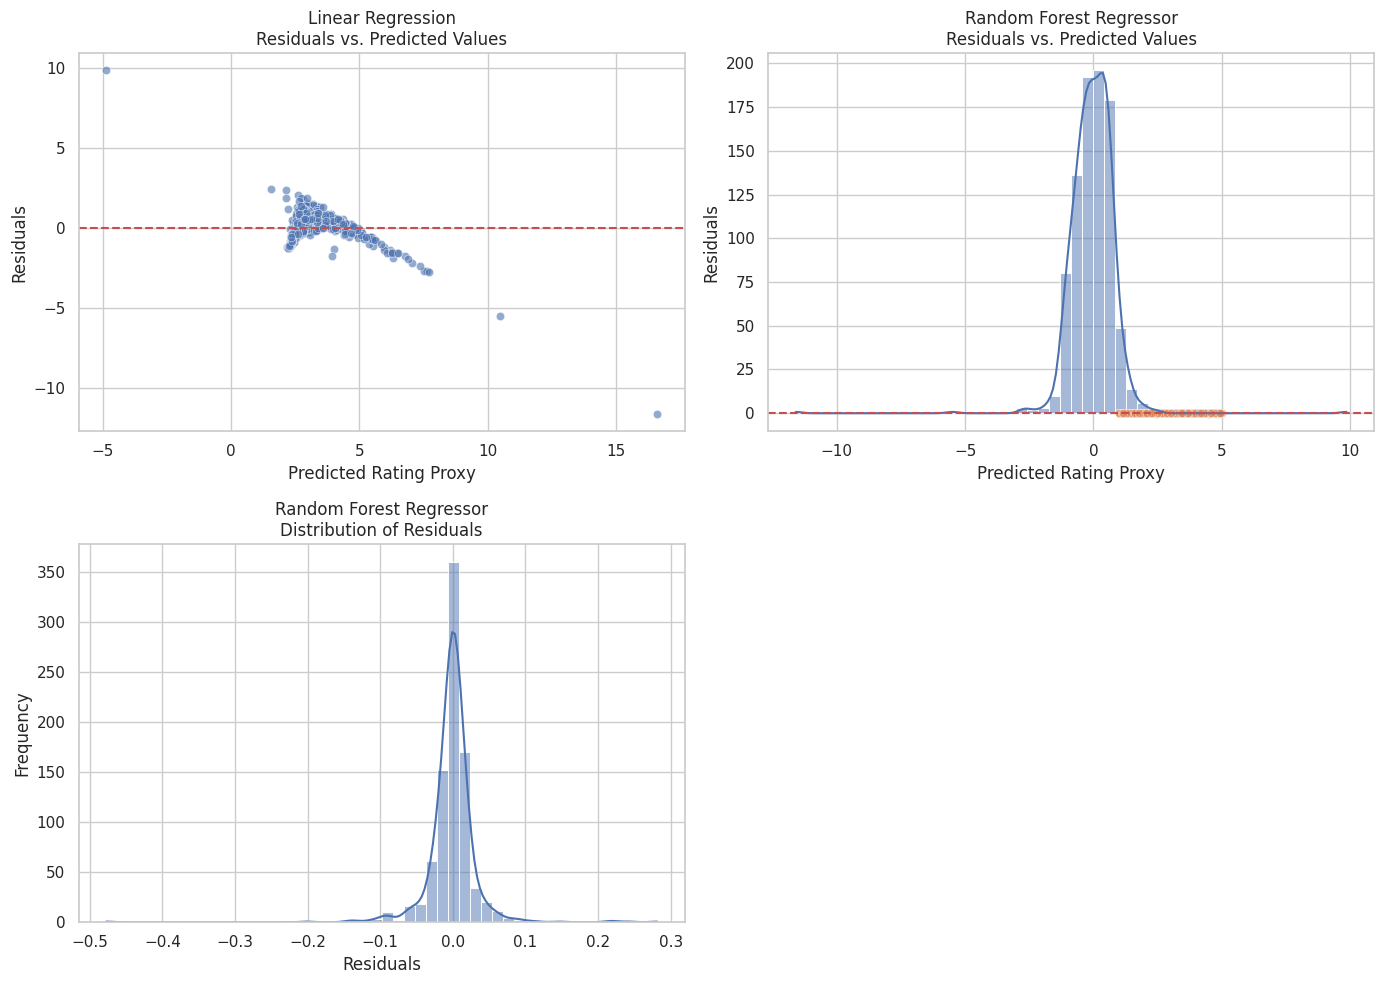

In [22]:
print("Performing Residual Analysis:")

plt.figure(figsize=(14, 10))
i = 1
for name in ["Linear Regression", "Random Forest Regressor"]:
    y_pred = predictions[name]
    residuals = y_test - y_pred

    # Residual Plot
    plt.subplot(2, 2, i)
    sns.scatterplot(x=y_pred, y=residuals, alpha=0.6)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.title(f'{name}\nResiduals vs. Predicted Values')
    plt.xlabel('Predicted Rating Proxy')
    plt.ylabel('Residuals')

    # Histogram of Residuals
    plt.subplot(2, 2, i + 1)
    sns.histplot(residuals, bins=50, kde=True)
    plt.title(f'{name}\nDistribution of Residuals')
    plt.xlabel('Residuals')
    plt.ylabel('Frequency')
    i += 1

plt.tight_layout()
plt.show()

# Code 21: Identify Best Model

In [23]:
print("Identifying the Best Model:")

# Find the model with the lowest RMSE
best_model_name = None
min_rmse = float('inf')

for name, metrics in model_metrics.items():
    if metrics['RMSE'] < min_rmse:
        min_rmse = metrics['RMSE']
        best_model_name = name

print(f"\nThe best model based on RMSE is: {best_model_name}")
print("Its performance metrics are:")
for metric, value in model_metrics[best_model_name].items():
    print(f"- {metric}: {value:.4f}")

print("\nBased on the test-set evaluation, this model achieved the lowest RMSE among the tested models.")

Identifying the Best Model:

The best model based on RMSE is: Random Forest Regressor
Its performance metrics are:
- MAE: 0.0184
- MSE: 0.0013
- RMSE: 0.0356

Based on the test-set evaluation, this model achieved the lowest RMSE among the tested models.


# Code 22: Final Predictions

In [24]:
print("Displaying final predictions for the first 20 test samples:")

final_predictions_df = pd.DataFrame({
    'Actual_Rating': y_test.reset_index(drop=True),
    'Linear_Regression_Prediction': predictions['Linear Regression'],
    'Random_Forest_Prediction': predictions['Random Forest Regressor']
})

display(final_predictions_df.head(20))

Displaying final predictions for the first 20 test samples:


,Actual_Rating,Linear_Regression_Prediction,Random_Forest_Prediction
0,3.306387,2.900975,3.304649
1,2.379776,2.480151,2.360088
2,1.824302,2.488271,1.834352
3,3.320673,3.018122,3.333432
4,3.141096,2.809660,3.139286
5,2.485925,2.495950,2.510133
6,2.416030,2.551820,2.422153
7,4.044510,4.599268,4.055398
8,4.424095,3.820718,4.412778
9,2.253504,2.662126,2.366476


# Code 23: Final ML Summary

- Target: `Rating_Proxy`
- Features: `Total_Spending`, `Total_Quantity`, `Number_of_Orders`, `Number_of_Products`, `Average_Order_Value`, `Average_Unit_Price`, `Purchase_Frequency`
- Train/Test Split: 80% training, 20% testing (`random_state=42`)
- Models: Linear Regression, Random Forest Regressor
- MAE: (refer to comparison table for values)
- MSE: (refer to comparison table for values)
- RMSE: (refer to comparison table for values)
- Best Model: (refer to section 19 for identification)
- Reason: Lowest RMSE on test-set evaluation
- Rating_Proxy limitation: Synthetic, not a real customer-provided rating

In [25]:
print("ML REGRESSION STAGE COMPLETED SUCCESSFULLY")

ML REGRESSION STAGE COMPLETED SUCCESSFULLY
